# Week 2 class

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/goodman-imperial/discrete-maths-classes/blob/main/week-2-class.ipynb)

In this week's class we'll dive into the prime factoring algorithm and see how different algorithmic choices can affect performance.

We'll start by importing some standard libraries, don't worry about understanding this if you don't speak Python.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# Introduction

Now we'll do the stupidest possible algorithm to count the number of primes less than n. This algorithm is even stupider than the one from the videos. See if you can understand how it works and why it's even stupider.

In [2]:
def stupidest_num_primes_less_than(n):
    def is_prime(n):
        if n==1:
            return False
        no_factors = True
        for j in range(2, n):
            if n%j==0:
                no_factors = False
        return no_factors
    count = 0
    for i in range(2, n+1):
        if is_prime(i):
            count += 1
    return count

Now we're going to plot the number of primes less than n and the same thing on a log-log plot. Later, we'll do some more plotting, and you can just re-use this code with slight modifications.

We also fit a best fit line to the log-log plot. Why is this useful? It gives us a rough idea of how fast the algorithm is growing (although it's not perfect). How does that work? Well, suppose that $\log y = a \log x + b$ for some constants $a$ and $b$, then by taking exponentials of both sides we can see that $y=e^b x^a$, in other words $y=\Theta(x^a)$ in complexity notation. So the slope of the best fit line of a log-log plot gives you an approximate value for the polynomial power if the function grows like a polynomial.

WARNING! This will give you a value even if the growth is NOT polynomial. Indeed, the examples below are not polynomial, this is just to get a rough idea of how quickly they're growing.

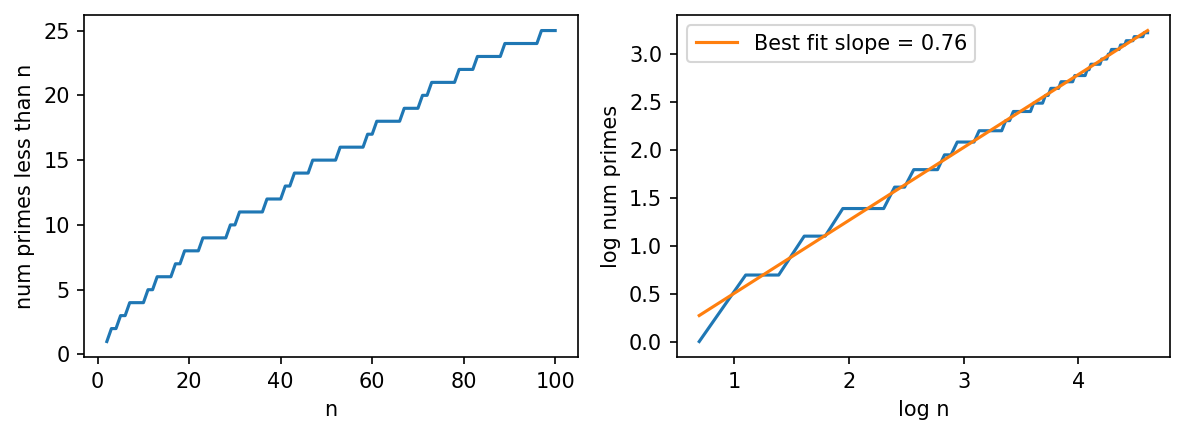

In [ ]:
# x axis will be n, the integers from 2 to 100
N = np.arange(2, 101)
# y axis will be the number of primes less than n
numprimes = np.array([stupidest_num_primes_less_than(n) for n in N])

# Matplotlib code (feel free to reuse)
plt.figure(figsize=(8, 3), dpi=150)      # create a figure with width 8 and height 3
plt.subplot(121)                         # first subplot on the left
plt.plot(N, numprimes)                   # plot N on the x-axis and numprimes on the y-axis
plt.xlabel('n')                          # label axes
plt.ylabel('num primes less than n')
plt.subplot(122)                         # second subplot on the right will be log-log
plt.plot(np.log(N), np.log(numprimes))   # np.log uses function log from numpy package
# Now we fit a line (polynomial of degree 1) to the log-log data
# this returns [slope, intercept] of the best fit line
slope, intercept = np.polyfit(np.log(N), np.log(numprimes), 1)
plt.plot(np.log(N), slope*np.log(N)+intercept, label=f'Best fit slope = {slope:.2f}')
# then we label it
plt.xlabel('log n')
plt.ylabel('log num primes')
plt.legend(loc='best')
plt.tight_layout(); # and this makes everything use space nicely

# Class questions

## Q1: Count and plot the number of operations

The first task is to add code to the prime counting function to count the number of operations it does. Here's an example for a different function you can adapt.

In [13]:
operation_count = 0

def sum_of_n(n):
    global operation_count
    sum = 0
    operation_count += 1 # we set sum to 0
    for i in range(1, n+1):
        operation_count += 2 # we add 1 to i and compare to n+1
        sum += i
        operation_count += 1 # we add i to sum
    return sum

In this function you can see that the global variable ``operation_count`` starts at 0 and is increased repeatedly while the function is called. We've added 2 and then 1 in the loop body, but actually because constants don't matter for complexity notation, you can just add 1 in the loop body.

Right, now go ahead and adapt this idea to count the number of operations in ``stupidest_num_primes_less_than(n)``, and plot that and fit a best line to the log-log plot as above (just adapt that code).

Does it do what you'd expect from the lecture videos?

Best-fit log-log slope = 2.21


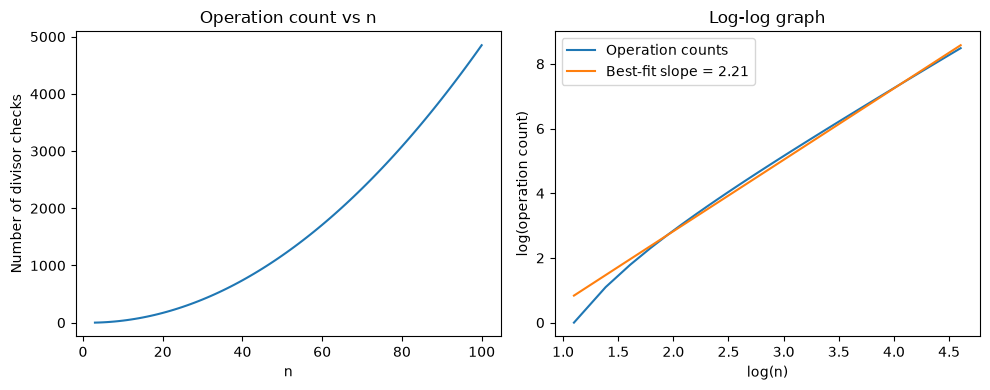

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# PART 1: PRIME-COUNTING FUNCTION
# ---------------------------------------

# Start the operation counter at zero
operation_count = 0

def stupidest_num_primes_less_than(n):

    # Inner function: checks whether a number is prime
    def is_prime(n):

        # Allows us to update the counter defined outside
        global operation_count

        if n == 1:
            return False

        no_factors = True

        # Try every possible divisor from 2 to n-1
        for j in range(2, n):

            # Count ONE operation for each divisor check
            operation_count += 1

            # If n is divisible by j, it isn't prime
            if n % j == 0:
                no_factors = False

        return no_factors

    # Count how many prime numbers we find
    count = 0

    # Test every number from 2 up to AND INCLUDING n
    for i in range(2, n + 1):

        if is_prime(i):
            count += 1

    return count


# ---------------------------------------
# PART 2: COLLECT OPERATION COUNTS
# ---------------------------------------

# Test input sizes from 3 to 100
# Start at 3 because log(0) is undefined,
# and n=2 produces zero divisor checks
N = np.arange(3, 101)

# Empty list to store the operation counts
operations = []

for n in N:

    # IMPORTANT: Reset before EACH experiment
    operation_count = 0

    # Run the algorithm for this input size
    stupidest_num_primes_less_than(n)

    # Save the resulting operation count
    operations.append(operation_count)


# ---------------------------------------
# PART 3: CALCULATE BEST-FIT LINE
# ---------------------------------------

# Take logarithms of input sizes and operation counts
log_N = np.log(N)
log_operations = np.log(operations)

# Fit a straight line: y = slope*x + intercept
slope, intercept = np.polyfit(log_N, log_operations, 1)

# Print the slope so we can interpret it
print(f"Best-fit log-log slope = {slope:.2f}")


# ---------------------------------------
# PART 4: PLOT BOTH GRAPHS
# ---------------------------------------

plt.figure(figsize=(10, 4))

# GRAPH 1: Normal graph
plt.subplot(1, 2, 1)

plt.plot(N, operations)

plt.xlabel("n")
plt.ylabel("Number of divisor checks")
plt.title("Operation count vs n")


# GRAPH 2: Log-log graph
plt.subplot(1, 2, 2)

# Plot the logarithms of the measured operation counts
plt.plot(log_N, log_operations, label="Operation counts")

# Plot the straight best-fit line
plt.plot(
    log_N,
    slope * log_N + intercept,
    label=f"Best-fit slope = {slope:.2f}"
)

plt.xlabel("log(n)")
plt.ylabel("log(operation count)")
plt.title("Log-log graph")
plt.legend()

# Prevent the graphs from overlapping
plt.tight_layout()

# Display both graphs
plt.show()

The operation count increases quadratically with input size. The log-log graph is approximately linear, with a best-fit slope of 2.21. This is close to the theoretical exponent of 2, confirming that the algorithm has time complexity O(n²).

## Version from lectures

Now modify your code to use the slightly less naive algorithm given in the lectures, where you break out of the inner loop once you find that a number is not prime. Analyse this. How does it compare?

Best-fit log-log slope = 1.86


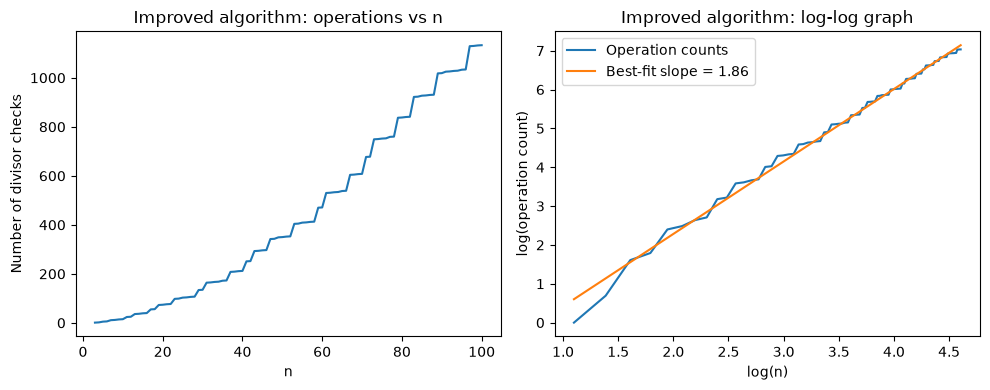

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# PART 1: IMPROVED PRIME-COUNTING FUNCTION
# ---------------------------------------

# Start the operation counter at zero
operation_count = 0

def num_primes_less_than(n):

    # Inner function: checks whether a number is prime
    def is_prime(n):

        # Allows us to update the counter defined outside
        global operation_count

        if n == 1:
            return False

        no_factors = True

        # Try possible divisors from 2 to n-1
        for j in range(2, n):

            # Count ONE operation for each divisor check
            operation_count += 1

            # If n is divisible by j, it isn't prime
            if n % j == 0:
                no_factors = False

                # NEW: Stop checking divisors immediately!
                break

        return no_factors

    # Count how many prime numbers we find
    count = 0

    # Test every number from 2 up to AND INCLUDING n
    for i in range(2, n + 1):

        if is_prime(i):
            count += 1

    return count


# ---------------------------------------
# PART 2: COLLECT OPERATION COUNTS
# ---------------------------------------

# Test input sizes from 3 to 100
N = np.arange(3, 101)

# Empty list to store operation counts
operations = []

for n in N:

    # Reset the counter before EACH experiment
    operation_count = 0

    # Run the improved algorithm
    num_primes_less_than(n)

    # Save the number of divisor checks
    operations.append(operation_count)


# ---------------------------------------
# PART 3: CALCULATE BEST-FIT LINE
# ---------------------------------------

# Take logarithms of input sizes and operation counts
log_N = np.log(N)
log_operations = np.log(operations)

# Fit a straight line: y = slope*x + intercept
slope, intercept = np.polyfit(log_N, log_operations, 1)

print(f"Best-fit log-log slope = {slope:.2f}")


# ---------------------------------------
# PART 4: PLOT BOTH GRAPHS
# ---------------------------------------

plt.figure(figsize=(10, 4))

# GRAPH 1: Normal graph
plt.subplot(1, 2, 1)

plt.plot(N, operations)

plt.xlabel("n")
plt.ylabel("Number of divisor checks")
plt.title("Improved algorithm: operations vs n")


# GRAPH 2: Log-log graph
plt.subplot(1, 2, 2)

# Plot the logarithms of the operation counts
plt.plot(log_N, log_operations, label="Operation counts")

# Plot the best-fit straight line
plt.plot(
    log_N,
    slope * log_N + intercept,
    label=f"Best-fit slope = {slope:.2f}"
)

plt.xlabel("log(n)")
plt.ylabel("log(operation count)")
plt.title("Improved algorithm: log-log graph")
plt.legend()

plt.tight_layout()
plt.show()

Adding break makes the algorithm more efficient because it stops checking divisors as soon as a factor is found. The log-log slope decreased from 2.21 to 1.86, and the number of operations at n = 100 fell by approximately 77%. The improved algorithm is therefore substantially faster over the tested range, although its worst-case time complexity remains O(n²).

## Prime factor algorithm

Actually, to check if a number $n$ is prime, you don't need to just every possible factor below $n$, only up to $\sqrt{n}$. Why? Because if $m$ is a factor of $n$, then $n/m$ must also be a factor, and at least one of $m$ or $n/m$ must be smaller than $\sqrt{n}$. If both $m$ and $n/m$ were larger than $\sqrt{n}$ then the product of them both would be larger than $n$, but the product is just $n$.

Adapt your code to use this idea and compare its performance. This is known as the prime factor algorithm.

Best-fit log-log slope = 1.53


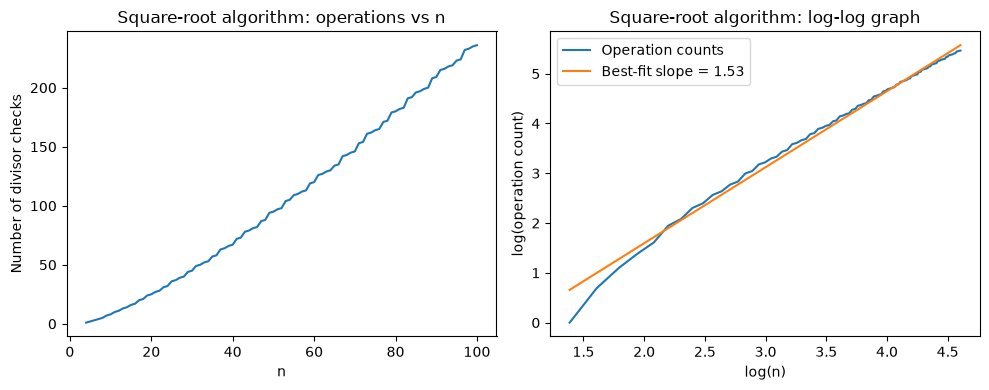

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from math import isqrt

# ---------------------------------------
# PART 1: PRIME-COUNTING FUNCTION
# ---------------------------------------

# Start the operation counter at zero
operation_count = 0

def prime_factor_num_primes_less_than(n):

    # Inner function: checks if a number is prime
    def is_prime(n):

        # Allows us to update the counter outside the function
        global operation_count

        # 1 is not prime
        if n == 1:
            return False

        no_factors = True

        # NEW: Only check divisors up to the square root of n
        # +1 because range() excludes its stopping value
        for j in range(2, isqrt(n) + 1):

            # Count one operation for each divisor check
            operation_count += 1

            # If n is divisible by j, it is not prime
            if n % j == 0:
                no_factors = False

                # Stop immediately when a divisor is found
                break

        return no_factors

    # Count how many prime numbers we find
    count = 0

    # Test every number from 2 up to AND INCLUDING n
    for i in range(2, n + 1):

        if is_prime(i):
            count += 1

    return count


# ---------------------------------------
# PART 2: COLLECT OPERATION COUNTS
# ---------------------------------------

# Test input sizes from 3 to 100
N = np.arange(4, 101)

# Empty list to store the operation counts
operations = []

for n in N:

    # Reset the counter before EACH experiment
    operation_count = 0

    # Run the new prime-counting algorithm
    prime_factor_num_primes_less_than(n)

    # Save the number of divisor checks
    operations.append(operation_count)


# ---------------------------------------
# PART 3: CALCULATE BEST-FIT LINE
# ---------------------------------------

# Take logarithms of the input sizes and operation counts
log_N = np.log(N)
log_operations = np.log(operations)

# Fit a straight line: y = slope*x + intercept
slope, intercept = np.polyfit(log_N, log_operations, 1)

# Display the measured slope
print(f"Best-fit log-log slope = {slope:.2f}")


# ---------------------------------------
# PART 4: PLOT BOTH GRAPHS
# ---------------------------------------

plt.figure(figsize=(10, 4))

# GRAPH 1: Normal graph
plt.subplot(1, 2, 1)

plt.plot(N, operations)

plt.xlabel("n")
plt.ylabel("Number of divisor checks")
plt.title("Square-root algorithm: operations vs n")


# GRAPH 2: Log-log graph
plt.subplot(1, 2, 2)

# Plot the logarithms of the operation counts
plt.plot(log_N, log_operations, label="Operation counts")

# Plot the best-fit straight line
plt.plot(
    log_N,
    slope * log_N + intercept,
    label=f"Best-fit slope = {slope:.2f}"
)

plt.xlabel("log(n)")
plt.ylabel("log(operation count)")
plt.title("Square-root algorithm: log-log graph")

plt.legend()
plt.tight_layout()
plt.show()

## Sieve of Eratosthenes

Finally, a much better algorithm is like the table method for the Fibonacci series. Rather than recomputing from scratch each time whether a number is prime, we re-use the calculations we've already made. In this case, start with a table of values saying all values from 2 to $n$ are prime. Loop through this from 2 to $n$, and if your value is prime, set all the multiples of it to be False. So in the first step you'd see that ``isprime[2]==True`` so you'd set ``isprime[4] = False``, ``isprime[6] = False`` and so on. Keep going until you've got to $\sqrt{n}$ and then count the number of values where ``isprime`` is True.

This algorithm is called the Sieve of Eratosthenes. Implement this algorithm and compare its performance.

Best-fit log-log slope = 1.41


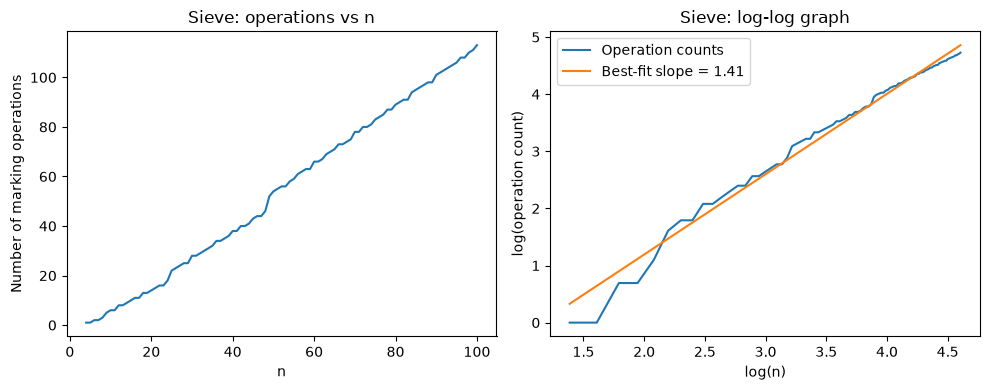

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from math import isqrt

# ---------------------------------------
# PART 1: SIEVE OF ERATOSTHENES
# ---------------------------------------

# Start the operation counter at zero
operation_count = 0

def sieve_num_primes_less_than(n):
    global operation_count

    # Create a list assuming every number is prime
    # We need n+1 positions to include n itself
    isprime = [True] * (n + 1)

    # 0 and 1 are NOT prime
    isprime[0] = False
    isprime[1] = False

    # Only need to check possible factors up to √n
    for i in range(2, isqrt(n) + 1):

        # Only process i if it has not been crossed out
        if isprime[i]:

            # Cross out multiples of i, starting at 2*i
            # The final i means increase by i each time
            for j in range(2 * i, n + 1, i):

                # Count one operation for each marking attempt
                operation_count += 1

                # Mark this multiple as NOT prime
                isprime[j] = False

    # Count how many numbers are still marked True
    # True counts as 1, False counts as 0
    return sum(isprime[2:])


# ---------------------------------------
# PART 2: COLLECT OPERATION COUNTS
# ---------------------------------------

# Test input sizes from 4 to 100
# Start at 4 so operation counts are positive
# (we cannot calculate log(0))
N = np.arange(4, 101)

# Empty list to store the operation counts
operations = []

for n in N:

    # Reset the counter before EACH experiment
    operation_count = 0

    # Run the sieve for this input size
    sieve_num_primes_less_than(n)

    # Save the number of marking operations
    operations.append(operation_count)


# ---------------------------------------
# PART 3: CALCULATE BEST-FIT LINE
# ---------------------------------------

# Take logarithms of input sizes and operation counts
log_N = np.log(N)
log_operations = np.log(operations)

# Fit a straight line: y = slope*x + intercept
slope, intercept = np.polyfit(log_N, log_operations, 1)

# Print the measured slope
print(f"Best-fit log-log slope = {slope:.2f}")


# ---------------------------------------
# PART 4: PLOT BOTH GRAPHS
# ---------------------------------------

plt.figure(figsize=(10, 4))

# GRAPH 1: Normal graph
plt.subplot(1, 2, 1)

plt.plot(N, operations)

plt.xlabel("n")
plt.ylabel("Number of marking operations")
plt.title("Sieve: operations vs n")


# GRAPH 2: Log-log graph
plt.subplot(1, 2, 2)

# Plot the logarithms of the operation counts
plt.plot(
    log_N,
    log_operations,
    label="Operation counts"
)

# Plot the best-fit straight line
plt.plot(
    log_N,
    slope * log_N + intercept,
    label=f"Best-fit slope = {slope:.2f}"
)

plt.xlabel("log(n)")
plt.ylabel("log(operation count)")
plt.title("Sieve: log-log graph")

plt.legend()
plt.tight_layout()
plt.show()

## Comparison

Finally, plot all the algorithms on the same axes to compare their performance.

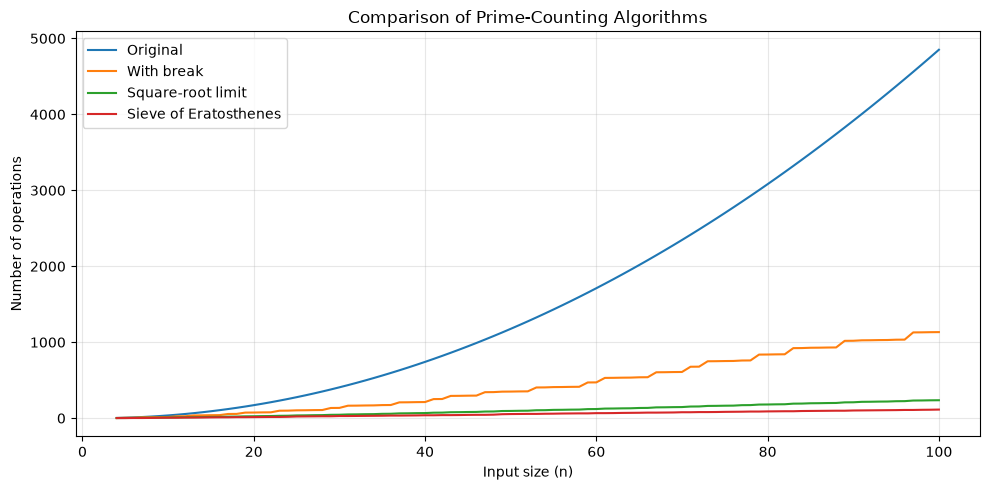

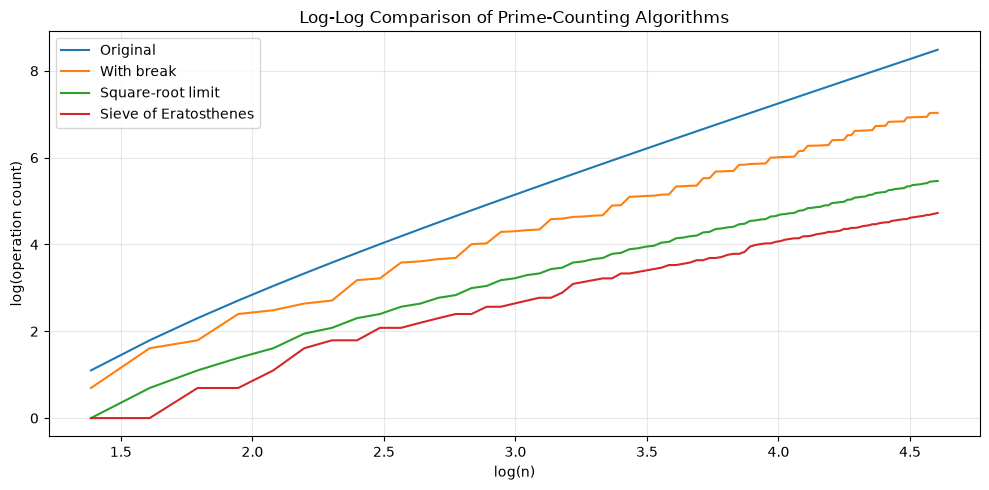

Primes up to 100:
Original: 25
With break: 25
Square-root: 25
Sieve: 25


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from math import isqrt

# ---------------------------------------
# PART 1: ORIGINAL ALGORITHM
# Checks ALL possible divisors
# ---------------------------------------

def original_algorithm(n):
    operations = 0
    count = 0

    for i in range(2, n + 1):
        is_prime = True

        for j in range(2, i):
            operations += 1  # Count each divisor check

            if i % j == 0:
                is_prime = False
                # No break: keep checking all divisors

        if is_prime:
            count += 1

    return count, operations


# ---------------------------------------
# PART 2: IMPROVED ALGORITHM
# Stops when a divisor is found
# ---------------------------------------

def break_algorithm(n):
    operations = 0
    count = 0

    for i in range(2, n + 1):
        is_prime = True

        for j in range(2, i):
            operations += 1

            if i % j == 0:
                is_prime = False
                break  # Stop checking this number

        if is_prime:
            count += 1

    return count, operations


# ---------------------------------------
# PART 3: SQUARE-ROOT ALGORITHM
# Only checks divisors up to √i
# ---------------------------------------

def sqrt_algorithm(n):
    operations = 0
    count = 0

    for i in range(2, n + 1):
        is_prime = True

        # Only check divisors up to √i
        for j in range(2, isqrt(i) + 1):
            operations += 1

            if i % j == 0:
                is_prime = False
                break

        if is_prime:
            count += 1

    return count, operations


# ---------------------------------------
# PART 4: SIEVE OF ERATOSTHENES
# Crosses out multiples instead
# ---------------------------------------

def sieve_algorithm(n):
    operations = 0

    # Assume all numbers are prime initially
    isprime = [True] * (n + 1)

    # 0 and 1 are not prime
    isprime[0] = False
    isprime[1] = False

    # Only process possible factors up to √n
    for i in range(2, isqrt(n) + 1):

        if isprime[i]:

            # Cross out multiples of i
            for j in range(2 * i, n + 1, i):
                operations += 1  # Count each marking attempt
                isprime[j] = False

    count = sum(isprime[2:])

    return count, operations


# ---------------------------------------
# PART 5: COLLECT RESULTS
# ---------------------------------------

# Use the SAME input sizes for all algorithms
N = np.arange(4, 101)

original_ops = []
break_ops = []
sqrt_ops = []
sieve_ops = []

for n in N:

    # Run all four algorithms
    _, op1 = original_algorithm(n)
    _, op2 = break_algorithm(n)
    _, op3 = sqrt_algorithm(n)
    _, op4 = sieve_algorithm(n)

    # Save their operation counts
    original_ops.append(op1)
    break_ops.append(op2)
    sqrt_ops.append(op3)
    sieve_ops.append(op4)


# ---------------------------------------
# PART 6: PLOT ALL FOUR ON SAME AXES
# ---------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(N, original_ops, label="Original")
plt.plot(N, break_ops, label="With break")
plt.plot(N, sqrt_ops, label="Square-root limit")
plt.plot(N, sieve_ops, label="Sieve of Eratosthenes")

plt.xlabel("Input size (n)")
plt.ylabel("Number of operations")
plt.title("Comparison of Prime-Counting Algorithms")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ---------------------------------------
# PART 7: LOG-LOG COMPARISON
# ---------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(np.log(N), np.log(original_ops),
         label="Original")

plt.plot(np.log(N), np.log(break_ops),
         label="With break")

plt.plot(np.log(N), np.log(sqrt_ops),
         label="Square-root limit")

plt.plot(np.log(N), np.log(sieve_ops),
         label="Sieve of Eratosthenes")

plt.xlabel("log(n)")
plt.ylabel("log(operation count)")
plt.title("Log-Log Comparison of Prime-Counting Algorithms")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ---------------------------------------
# PART 8: CHECK ALL ALGORITHMS AGREE
# ---------------------------------------

# All four should find 25 primes up to 100
print("Primes up to 100:")
print("Original:", original_algorithm(100)[0])
print("With break:", break_algorithm(100)[0])
print("Square-root:", sqrt_algorithm(100)[0])
print("Sieve:", sieve_algorithm(100)[0])